# Image learning, CNN ideas and research synthesis

What does an image classifier actually learn, and what would justify trusting its result?

Fall 2023.


# Predict a local response
A bright edge can create a filter response, but no response is itself a diagnosis. Predict whether a constant image gives a directional response. These original ellipse images have no clinical labels.

In [1]:
from demo import run, make_images, features, fit_centers, predict
import numpy as np
report = run()
print(report)

{'architecture': 'fixed3x3filters -> ReLU -> global mean pooling -> trained nearest centroid classifier', 'trained_CNN': False, 'train_images': 80, 'test_images': 40, 'test_confusion_true_rows_predicted_columns': [[20, 0], [0, 20]], 'contrasts': [1.0, 0.5, 0.0], 'test_accuracies': [1.0, 1.0, 0.5], 'checks': {'constant_image_zero_directional_response': True, 'valid_output_shape': True, 'transpose_swaps_features': True, 'finite_nonnegative_pooled_features': True}}


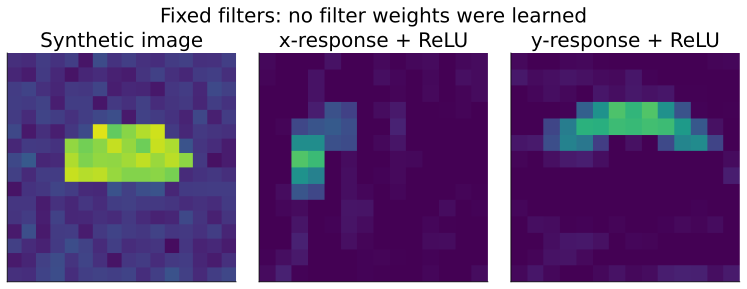

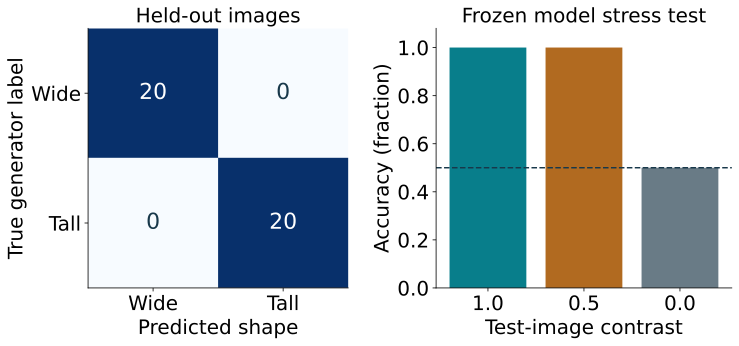

In [2]:
from IPython.display import SVG, display
display(SVG(filename="image-filters.svg"))
display(SVG(filename="image-evaluation.svg"))

## Interpret
Name the fixed and fitted parts. Read the confusion table with true rows first. Explain why full accuracy on this generator is not a medical claim.

In [3]:
train_images, train_labels = make_images(80, seed=10)
centers = fit_centers(features(train_images), train_labels)
chosen_contrast = 0.25  # Change this one number between 0 and 1 after predicting.
new_images, new_labels = make_images(40, seed=11, contrast=chosen_contrast)
print("Frozen-model accuracy:", np.mean(predict(features(new_images), centers) == new_labels))

Frozen-model accuracy: 1.0


## Modify and synthesize
Predict the zero-contrast result, then run it without refitting centers. Explain the missing signal. Finally write your existing project’s target, evidence, check and limitation; this discussion does not change the semester-end project deadline.